In [5]:
import pandas as pd
iris=pd.read_csv(r"F:\研一数据仓库\实验一\iris.csv")
X=iris.drop('species',axis=1)#特征矩阵
y=iris['species']#目标数组
print(X)

     sepal_length  sepal_width  petal_length  petal_width
0             5.1          3.5           1.4          0.2
1             4.9          3.0           1.4          0.2
2             4.7          3.2           1.3          0.2
3             4.6          3.1           1.5          0.2
4             5.0          3.6           1.4          0.2
..            ...          ...           ...          ...
145           6.7          3.0           5.2          2.3
146           6.3          2.5           5.0          1.9
147           6.5          3.0           5.2          2.0
148           6.2          3.4           5.4          2.3
149           5.9          3.0           5.1          1.8

[150 rows x 4 columns]


In [31]:
import numpy as np
class kNNClassifier:
    def __init__(self,k=1):
        self. Xtr = None
        self. ytr = None
        self. k = k
    def train(self, X, y):
        self.Xtr=X
        self.ytr=y
    def predict(self, X):
        num_test = X. shape[0]
        Ypred=np.zeros(num_test,dtype=self.ytr.dtype)
        for i in range(num_test):
            distances = np. sqrt(np.sum((self.Xtr-X[i,:])**2,axis=1))
            sorted_indices=np.argsort(distances)
            classCount={}
            for j in range(self.k):
                vote_j_label=self.ytr[sorted_indices[j]]
                classCount[vote_j_label] = classCount.get(vote_j_label, 0) + 1
            sortedClassCount=sorted(classCount.items(),key=lambda d:d[1],reverse=True)
            Ypred[i]=sortedClassCount[0][0]
        return Ypred


In [32]:
# 划分数据集
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=0
)

# 创建对象并训练（先运行前面修正后的类定义）
clf = kNNClassifier(k=3)
clf.train(X_train, y_train)

# 预测并评估
from sklearn import metrics

y_pred = clf.predict(X_test)

score = metrics.accuracy_score(y_test, y_pred)
print("测试集上分类准确率为：{:.4f}".format(score))

mat = metrics.confusion_matrix(y_test, y_pred)
print("混淆矩阵：\n", mat)

print("分类性能报告：")
print(metrics.classification_report(y_test, y_pred, zero_division=0))

测试集上分类准确率为：0.9737
混淆矩阵：
 [[13  0  0]
 [ 0 15  1]
 [ 0  0  9]]
分类性能报告：
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       1.00      0.94      0.97        16
   virginica       0.90      1.00      0.95         9

    accuracy                           0.97        38
   macro avg       0.97      0.98      0.97        38
weighted avg       0.98      0.97      0.97        38



In [37]:
from sklearn.neighbors import KNeighborsClassifier


In [40]:
knn=KNeighborsClassifier(n_neighbors=5)

#【例 6.5】〗】 评一个简 估 单 的 k近邻分类器。
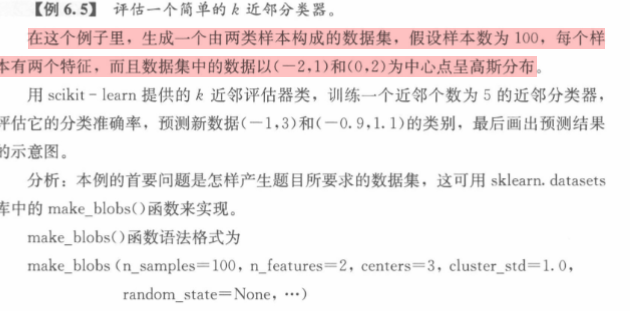

测试集上的准确率: 0.92
scikit-learn中KNeighborsClassifier预测结果
sckit-learn中的预测结果:[1 1]


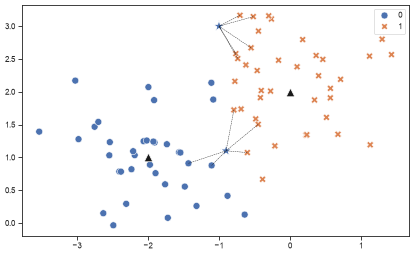

In [69]:
from sklearn. datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier
from sklearn import set_config
set_config(display="text")
import numpy as np
#center 是分布的中心点 或者固定中置的数组 。它是 int 型 (默值认为 3) 或 形状为nA, on 个特征) 的 数组 ,可选参数 。
centers=[(-2,1),(0,2)]


#生成数据集
X, y=make_blobs(n_samples=100, centers= centers, random_state=0, cluster_std=0.6)
from sklearn. model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=0) ## 拆分数据集

#初始化模型
knn=KNeighborsClassifier(n_neighbors=5)


#训练模型
knn.fit(X_train,y_train)

test_score = knn.score(X_test,y_test) ##在测试集上测试分类准确率
print( "测试集上的准确率:",test_score)

#评估模型
X_sample=np. array([[-1,3],[-0.9,1.1]])
# scikit - learn 的输入数据必须是二维数组
y_sample=knn.predict(X_sample)
print("scikit-learn中KNeighborsClassifier预测结果")

#预测新数据
X_sample=np.array([[-1,3],[-0.9,1.1]])
y_sample=knn.predict(X_sample)
print("sckit-learn中的预测结果:{}".format(y_sample))
neighbors=knn.kneighbors(X_sample,return_distance=False)


#预测结果可视化
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="ticks")

plt.figure(figsize=(10,6),dpi=50)
sns.scatterplot(x=X_sample[:,0],y=X_sample[:,1],marker='*',hue=y_sample,s=300,legend=False)
sns.scatterplot(x=X_train[:,0],y=X_train[:,1],marker='o',hue=y_train,s=100,style=y_train)

c=np.array(centers)
sns.scatterplot(x=c[:,0],y=c[:,1],s=150,marker='^',color='k')

for i in neighbors[0]:
    plt.plot([X_train[i][0],X_sample[0][0]],[X_train[i][1],X_sample[0][1]],
             'k--',linewidth=0.6)
for i in neighbors[1]:
    plt.plot([X_train[i][0],X_sample[1][0]],[X_train[i][1],X_sample[1][1]],'k--',linewidth=0.6)






###6.2.2例子糖尿病预测